<h1>Содержание<span class="tocSkip"></span></h1>
<div class="toc"><ul class="toc-item"><li><span><a href="#Первичный-анализ" data-toc-modified-id="Первичный-анализ-1"><span class="toc-item-num">1&nbsp;&nbsp;</span>Первичный анализ</a></span></li><li><span><a href="#Обучение-моделей" data-toc-modified-id="Обучение-моделей-2"><span class="toc-item-num">2&nbsp;&nbsp;</span>Обучение моделей</a></span></li><li><span><a href="#Тестирование-на-финальной-модели" data-toc-modified-id="Тестирование-на-финальной-модели-3"><span class="toc-item-num">3&nbsp;&nbsp;</span>Тестирование на финальной модели</a></span></li></ul></div>

#  Прогнозирование заказов такси

Компания «Чётенькое такси» собрала исторические данные о заказах такси в аэропортах. Чтобы привлекать больше водителей в период пиковой нагрузки, нужно для прогноза заказов такси на следующий час.

Значение метрики *RMSE* на тестовой выборке должно быть не больше 48.

## Первичный анализ

In [1]:
!pip install lightgbm -q

In [2]:
#Импорт необходимых библиотек
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import lightgbm as lgb
from statsmodels.tsa.seasonal import seasonal_decompose
from sklearn.model_selection import (
    train_test_split,
    cross_val_score,
    TimeSeriesSplit
)
from sklearn.metrics import (
    mean_squared_error,
    make_scorer
)
from sklearn.linear_model import LinearRegression

In [3]:
#Загрузка файла и последующего сохранения в датафрейм, делая колонку со временем индексом для последующего ресамплирования
df = pd.read_csv('/datasets/taxi.csv', parse_dates=['datetime'], index_col='datetime')
#Вывод первых пяти строк и общей информации о нем
display(df.head(5))
print(df.info())

,num_orders
datetime,
2018-03-01 00:00:00,9
2018-03-01 00:10:00,14
2018-03-01 00:20:00,28
2018-03-01 00:30:00,20
2018-03-01 00:40:00,32


<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 26496 entries, 2018-03-01 00:00:00 to 2018-08-31 23:50:00
Data columns (total 1 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   num_orders  26496 non-null  int64
dtypes: int64(1)
memory usage: 414.0 KB
None


In [4]:
#Проверка столбца со временем в качестве индекса датафрейма
print(df.index)

DatetimeIndex(['2018-03-01 00:00:00', '2018-03-01 00:10:00',
               '2018-03-01 00:20:00', '2018-03-01 00:30:00',
               '2018-03-01 00:40:00', '2018-03-01 00:50:00',
               '2018-03-01 01:00:00', '2018-03-01 01:10:00',
               '2018-03-01 01:20:00', '2018-03-01 01:30:00',
               ...
               '2018-08-31 22:20:00', '2018-08-31 22:30:00',
               '2018-08-31 22:40:00', '2018-08-31 22:50:00',
               '2018-08-31 23:00:00', '2018-08-31 23:10:00',
               '2018-08-31 23:20:00', '2018-08-31 23:30:00',
               '2018-08-31 23:40:00', '2018-08-31 23:50:00'],
              dtype='datetime64[ns]', name='datetime', length=26496, freq=None)


In [5]:
#Копирую датафрейм для дальнейшего ресамплирования по дням
df_1 = df.copy()

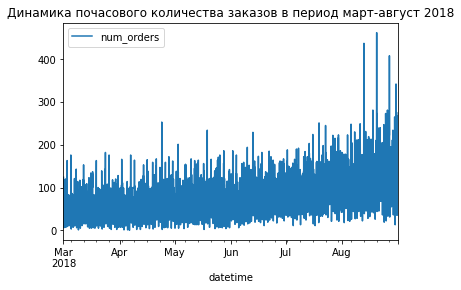

In [6]:
#Ресамплирование по часу и его визуализация
df = df.resample('1H').sum()
df.plot(title = 'Динамика почасового количества заказов в период март-август 2018');

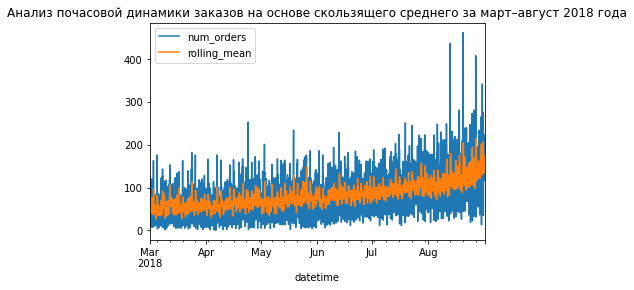

In [7]:
#Построение скользящего среднего и его визуализация
df['rolling_mean'] = df.shift().rolling(10).mean()
df.plot(title = 'Анализ почасовой динамики заказов на основе скользящего среднего за март–август 2018 года');

**Вывод:** В результате первичного анализа данных установлено, что датасет содержит информацию о количестве заказов такси и времени их совершения. После проведения ресамплирования по часовому интервалу был построен график временного ряда, на котором наблюдаются значительные колебания значений. Для снижения влияния случайного шума и выявления общей тенденции было рассчитано скользящее среднее с окном 10 наблюдений. Сглаженный график показывает чётко выраженный возрастающий тренд в период с марта по август 2018 года, что свидетельствует о нестационарности временного ряда.

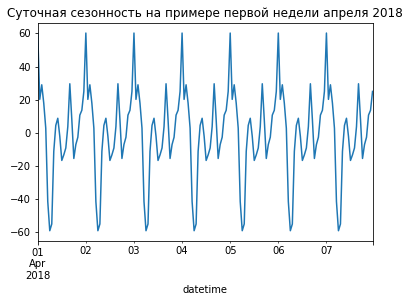

In [8]:
#Анализ суточной сезонности 
decomposed = seasonal_decompose(df['num_orders'], model='additive', period=24)
decomposed.seasonal['2018-04':'2018-04-07'].plot(title='Суточная сезонность на примере первой недели апреля 2018');

**Вывод:** При декомпозиции временного ряда с периодом 24 часа наблюдается ярко выраженная суточная закономерность.
Минимальные значения приходятся на ночные часы (0:00–6:00), когда активность пользователей значительно ниже среднего уровня.
Затем виден первый подъём в утренние часы (7:00–10:00) — это утренний пик, вероятно, связанный с началом рабочего дня и поездками на работу. 

В дневное время (12:00–15:00) фиксируется второй, более умеренный пик, который может быть обусловлен обеденными перерывами и дневными делами. 

Наиболее выраженный пик приходится на вечерние часы (18:00–22:00) — именно в этот период наблюдается наибольшее количество заказов, что логично для времени, когда пользователи возвращаются домой и активно пользуются сервисом. 

Таким образом, в течение суток можно выделить три характерных периода активности, с максимальной нагрузкой в вечерние часы и минимальной — ночью.

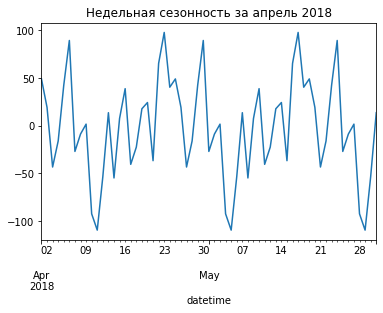

In [9]:
#Ресамплирование по дням для последующего анализа недельной сезонности
df_weekly = df_1.resample('1D').sum()
#Анализ недельной сезонности 
decomposed_weekly = seasonal_decompose(df_weekly['num_orders'], model='additive', period=24)
decomposed_weekly.seasonal['2018-04':'2018-05'].plot(title='Недельная сезонность за апрель 2018');

**Вывод:** После декомпозиции временного ряда заказов была выделена сезонная компонента с недельным периодом.
На графике наблюдаются регулярные колебания количества заказов в течение недели.
Значения сезонной компоненты колеблются в диапазоне от -100 до +100, что указывает на заметное влияние недельных циклов.
- В пиковые дни количество заказов выше среднего уровня (вероятно, выходные дни).
- В начале недели наблюдается спад активности клиентов.
- Сезонность стабильна и повторяется из недели в неделю, что подтверждает наличие устойчивой недельной закономерности.

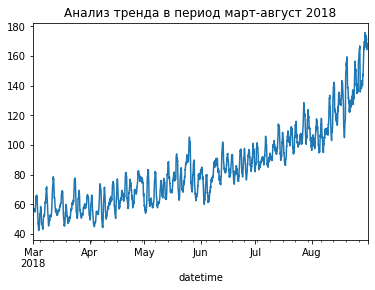

In [10]:
#Анализ тренда
decomposed.trend.plot(title='Анализ тренда в период март-август 2018');

**Вывод:** Анализ тренда за период март–август 2018 года показывает устойчивый рост количества заказов.
При этом характер тренда нелинейный: с марта по май наблюдается умеренное увеличение, а начиная с июня темпы роста ускоряются.
К августу уровень заказов увеличивается почти втрое по сравнению с мартом. Подобная динамика может быть связана с сезонным повышением спроса в летний период, расширением аудитории сервиса или маркетинговыми активностями. Таким образом, можно заключить, что общий тренд за рассматриваемый период является сильно возрастающим с ускорением роста.

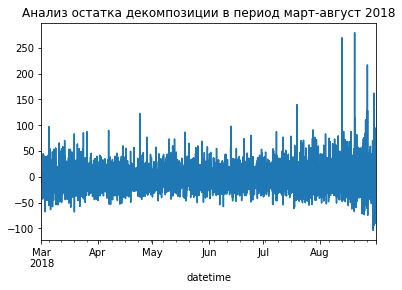

In [11]:
#Анализ остатка декомпозиции
decomposed.resid.plot(title='Анализ остатка декомпозиции в период март-август 2018');

**Вывод:** Остаточная компонента колеблется вокруг нулевой линии, что говорит о корректности выделения тренда и сезонности.
Однако в конце периода (июль–август) наблюдается увеличение амплитуды шума и появление выбросов. Это может свидетельствовать о росте непредсказуемости данных или изменении структуры временного ряда. При построении прогностической модели данные этого периода следует учитывать с осторожностью — при включении их в тестовую выборку точность модели может снизиться из-за увеличения дисперсии остатков.

## Обучение моделей

In [12]:
#Функция для генерации признаков
def make_features(df, max_lag, rolling_mean_size):
    df['hour'] = df.index.hour
    df['day'] = df.index.day
    df['dayofweek'] = df.index.dayofweek
    #Краткосрочная динамика
    for lag in range(1, max_lag + 1):
        df[f'lag_{lag}'] = df['num_orders'].shift(lag)
    #Суточная сезонность
    for lag in [24, 168]:
        df[f'lag_{lag}'] = df['num_orders'].shift(lag)
    df['rolling_mean'] = (
        df['num_orders']
        .shift(1)
        .rolling(window=rolling_mean_size)
        .mean()
    )

make_features(df, 5, 24)
print(df.head(5))

                     num_orders  rolling_mean  hour  day  dayofweek  lag_1  \
datetime                                                                     
2018-03-01 00:00:00         124           NaN     0    1          3    NaN   
2018-03-01 01:00:00          85           NaN     1    1          3  124.0   
2018-03-01 02:00:00          71           NaN     2    1          3   85.0   
2018-03-01 03:00:00          66           NaN     3    1          3   71.0   
2018-03-01 04:00:00          43           NaN     4    1          3   66.0   

                     lag_2  lag_3  lag_4  lag_5  lag_24  lag_168  
datetime                                                          
2018-03-01 00:00:00    NaN    NaN    NaN    NaN     NaN      NaN  
2018-03-01 01:00:00    NaN    NaN    NaN    NaN     NaN      NaN  
2018-03-01 02:00:00  124.0    NaN    NaN    NaN     NaN      NaN  
2018-03-01 03:00:00   85.0  124.0    NaN    NaN     NaN      NaN  
2018-03-01 04:00:00   71.0   85.0  124.0    NaN    

In [13]:
#Подготовка данных для обучения

train, test = train_test_split(df, test_size=0.1, shuffle = False)
train = train.dropna()

X_train = train.drop(columns=['num_orders'])
y_train = train['num_orders']

X_test = test.drop(columns=['num_orders'])
y_test = test['num_orders']

In [14]:
#Обучение модели линейной регрессии
model_lr = LinearRegression()
model_lr.fit(X_train, y_train)

rmse_scorer = make_scorer(mean_squared_error, squared=False)

# Кросс-валидация с сохранением порядка времени
tscv = TimeSeriesSplit(n_splits=5)

score_lr = cross_val_score(model_lr, X_train, y_train, scoring=rmse_scorer, cv=tscv, n_jobs=-1)

print(f'RMSE на кросс-валидации для модели линейной регрессии = {np.mean(score_lr):.1f}')

RMSE на кросс-валидации для модели линейной регрессии = 23.1


In [15]:
#Обучение модели LightGBM
model_lgb = lgb.LGBMRegressor(
    n_estimators=100,
    max_depth=6,
    num_leaves=31,
    n_jobs=-1,
    random_state=42
)
model_lgb.fit(X_train, y_train)

score_lgb = cross_val_score(model_lgb, X_train, y_train, scoring=rmse_scorer, cv=tscv, n_jobs=-1)

print(f'RMSE на кросс-валидации для модели LightGBM = {np.mean(score_lgb):.1f}')

RMSE на кросс-валидации для модели LightGBM = 23.3


**Вывод:** Обе модели на этапе кросс-валидации показали высокое качество, удовлетворяющее требованию задачи (RMSE < 48). Однако для финального тестирования целесообразно выбрать модель линейной регрессии, так как она продемонстрировала немного более точные результаты по сравнению с моделью LightGBM  — RMSE 23.1 против 23.3 соответственно.

## Тестирование на финальной модели 

In [16]:
#Делаю финальное предсказание на тестовой выборке с использованием лучшей модели
y_pred = model_lr.predict(X_test)
#Считаю rmse для финального предсказания
rmse = mean_squared_error(y_test, y_pred, squared=False)
print(f'RMSE на тестовой выборке = {rmse:.1f}')

RMSE на тестовой выборке = 35.2


**Вывод:** На тестовой выборке значение метрики RMSE составило 35.2, что свидетельствует о высокой точности прогноза и подтверждает адекватность выбранной модели. Такой результат значительно лучше установленного порогового значения (RMSE < 48), что говорит о хорошей способности модели предсказывать количество заказов такси на следующий час.

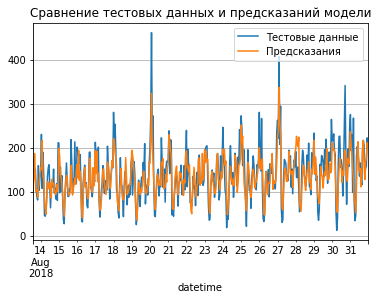

In [17]:
res = pd.DataFrame({
    'Тестовые данные': y_test,
    'Предсказания': y_pred
})

res.plot(y=['Тестовые данные', 'Предсказания'], grid=True, title='Сравнение тестовых данных и предсказаний модели');

**Вывод:** На графике видно, что модель линейной регрессии достаточно точно повторяет динамику фактических значений на тестовом периоде (август 2018 года).
Предсказания хорошо следуют общей тенденции и отражают изменения спроса по времени.

При этом наблюдаются отдельные отклонения — особенно в датах 20, 26–27 и 30–31 августа.
Эти всплески не были предсказаны моделью, что, вероятно, связано с увеличением шума и наличием выбросов в августовском периоде, выявленных ранее при анализе остатков.
Подобные колебания могут быть вызваны внешними факторами (например, изменением поведения пользователей или аномальными событиями), которые не отражены в текущих признаках модели.

В целом модель демонстрирует адекватное качество прогноза и хорошо описывает закономерности ряда, несмотря на наличие шумовых выбросов в конце периода.

**Итоговый вывод:**
В рамках проекта была разработана модель прогнозирования количества заказов такси на следующий час для компании «Чётенькое такси». Финальная модель линейной регрессии достигла RMSE = 35.2 на тестовой выборке, что значительно ниже порогового значения (48).

Анализ временного ряда выявил три ключевые закономерности для планирования:
1) Суточная сезонность: максимальная нагрузка приходится на вечерние часы (18:00–22:00), минимальная — на ночь (0:00–6:00). Утренний (7:00–10:00) и дневной (12:00–15:00) пики выражены умеренно. \
2) Недельная сезонность: устойчивые колебания спроса в течение недели со спадом в начале недели и ростом к выходным. \
3) Долгосрочный тренд: устойчивый рост количества заказов с марта по август с ускорением в летний период.

**Рекомендации для бизнеса:**
- Увеличивать количество доступных водителей в вечерние часы и выходные дни — периоды пиковой нагрузки
- Использовать модель для автоматического планирования смен водителей за час до начала пикового периода
- Учитывать сезонный рост спроса в летние месяцы при долгосрочном планировании ресурсов
- Рассмотреть расширение признакового пространства (погода, события в городе, праздники) для повышения точности прогноза в периоды аномальных выбросов